# Deel 1 - Les 5 - Boosted Trees en SVM

## **Stap 1:** Libraries

In [43]:
# Installeer benodigde packages (indien nog niet aanwezig)
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import copy  # to copy variables
import pandas as pd
import matplotlib.image as img # To load the images
from sklearn.ensemble import RandomForestClassifier # The machine learning model 
from sklearn.model_selection import train_test_split


## **Stap 2:** Data

### 2.1. Data laden en exploratie  
- Laten we beginnen met het laden van een afbeelding van een enkele bloem om de datastructuur te begrijpen. We zullen bekijken hoe afbeeldingen worden opgeslagen en welke informatie ze bevatten
- We gebruiken de functie `imread` van matplotlib om de afbeelding in het geheugen te laden
- Laten we nu de afbeelding weergeven die we zojuist hebben geladen, om te controleren of deze correct is ingelezen

In [4]:
bloem1 = img.imread('0006.png')

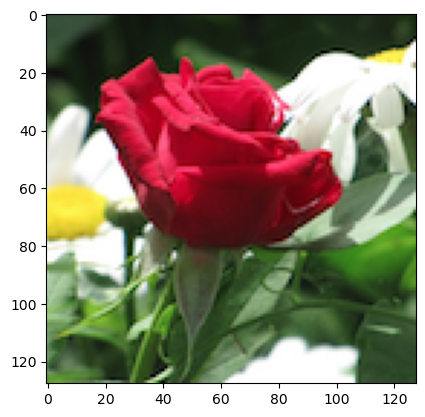

In [5]:
plt.imshow(bloem1)

2 assen: 
- x & y: pixels. gaat niet tot 130. resolutie: 120x120

Laat ons de structuur van de figuur bekijken

In [6]:
bloem1.shape

(128, 128, 4)

Dit is interessant. De vorm van het data-object is $128$ x $128$ x $4$. Het lijkt erop dat de afmetingen van de afbeelding 256 bij 256 pixels zijn. De 4 geeft aan dat de data uit 4 lagen bestaat; waarschijnlijk zijn er 3 voor kleur en 1 voor iets anders. Laten we elke laag afzonderlijk plotten om te zien wat we hebben.

Merk op dat indexering in Python bij 0 begint. De eerste laag heeft dus index 0, de tweede laag index 1, enzovoort.

Laten we nu elke kleurlaag afzonderlijk bekijken om te begrijpen welke informatie deze bevat:

layer 1:


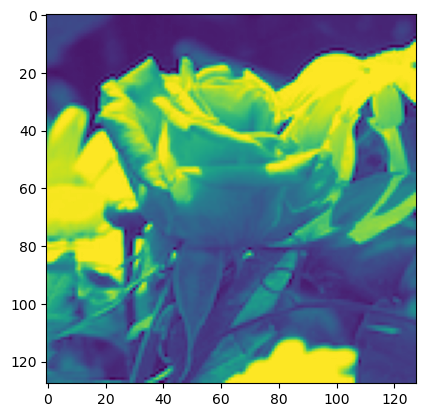

layer 2:


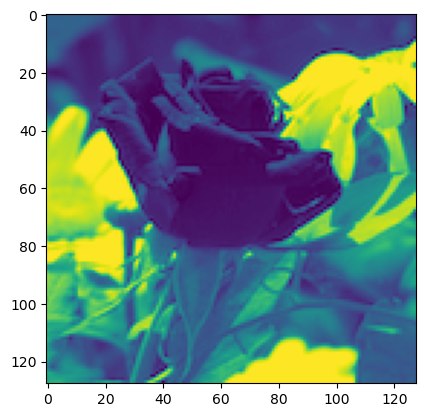

layer 3:


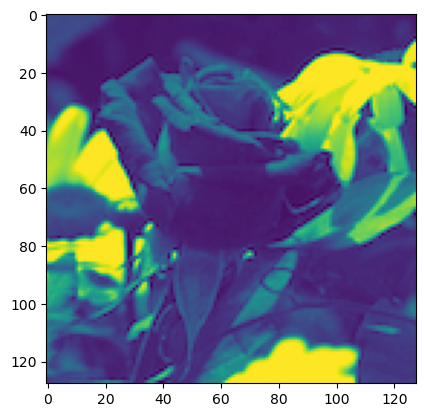

layer 4:


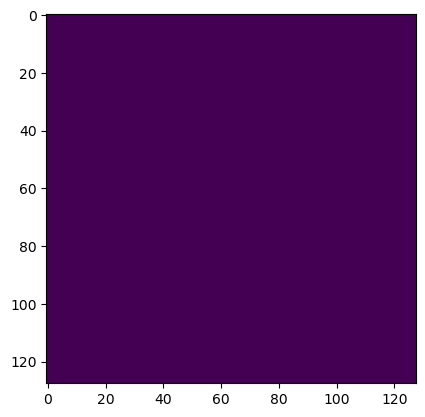

In [ ]:
# de vier lagen van de afbeelding apart bekijken
layer1 = bloem1[:,:,0] # First layer
layer2 = bloem1[:,:,1] # Second layer
layer3 = bloem1[:,:,2] # Third layer
layer4 = bloem1[:,:,3] # Fourth layer

for i in range(0,4):
    print(f"layer {i+1}:")
    plt.imshow(bloem1[:,:,i])
    plt.show()

Oké, er zijn een aantal dingen die we kunnen waarnemen.
- Ten eerste heeft layer4 voor alles dezelfde waarde. Waarschijnlijk heeft layer 4 iets te maken met de helderheid van de afbeelding of iets dergelijks. Wat het ook is, we hebben het duidelijk niet nodig.
- Alle lagen lijken te bestaan ​​uit blauw, groen en geel. Hoe zit dat? Dit heeft waarschijnlijk te maken met de standaardinstelling van `imshow`, waarbij hoge waarden worden weergegeven in felgeel en lagere waarden in donkerder groen/blauw. 
- Hoe kunnen we dit testen? Misschien kunnen we de oorspronkelijke afbeelding nemen en bepaalde lagen op nul zetten om te zien wat er gebeurt.

Laten we onze hypothese over RGB-lagen testen door elk kleurkanaal te isoleren. We maken kopieën van de afbeelding en zetten twee lagen op nul, zodat we telkens slechts één kleur zien:

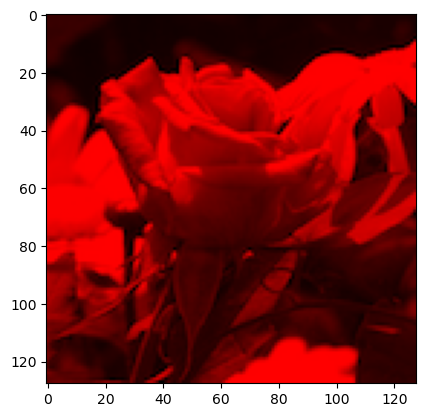

In [9]:
# Laag 1 (Laag 2 en 3 nul)
bloem1_copy = copy.deepcopy(bloem1)

bloem1_copy[:,:,1] = np.zeros((128, 128)) # zet laag 2 allemaal op nul
bloem1_copy[:,:,2] = np.zeros((128, 128)) # zet laag 3 allemaal op nul

plt.imshow(bloem1_copy)

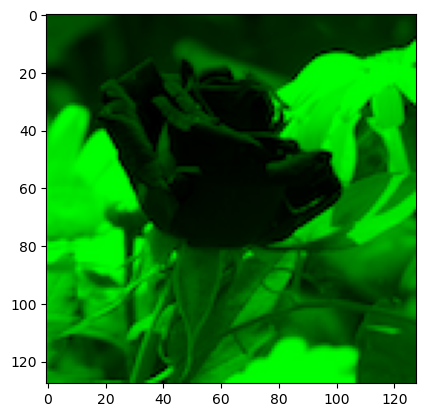

In [10]:
# Laag 2 (Laag 1 en 3 nul)
bloem1_copy = copy.deepcopy(bloem1)
bloem1_copy[:,:,0] = np.zeros((128, 128)) # zet laag 1 allemaal op nul
bloem1_copy[:,:,2] = np.zeros((128, 128)) # zet laag 3 allemaal op nul
plt.imshow(bloem1_copy)

Oké, nu komen we ergens. We zetten laag 2 en 3 (index 1 en 2, weet je nog) op nul en de uiteindelijke afbeelding is volledig rood. We kunnen concluderen dat laag 1 de rode kleur bevat. Laten we er dus voorlopig van uitgaan dat de eerste laag inderdaad rood is en de volgende lagen groen en blauw (RGB). Laten we alle lagen eens bekijken!

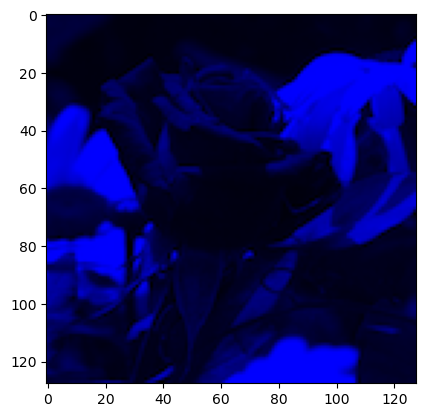

In [11]:
# Laag 3 (Laag 1 en 2 nul)
bloem1_copy = copy.deepcopy(bloem1)
bloem1_copy[:,:,0] = np.zeros((128, 128)) # zet laag 1 allemaal op nul
bloem1_copy[:,:,1] = np.zeros((128, 128)) # zet laag 2 allemaal op nul
plt.imshow(bloem1_copy)

### 2.2. Berekenen van de features

We willen onze afbeelding kwantificeren aan de hand van enkele variabelen die we moeten berekenen. In de les hebben we het voorbeeld met de som gezien. Laten we dus de som voor elke kleur berekenen en kijken hoe we die gegevens kunnen samenbrengen in een matrixachtige structuur (een ndarray in Python).

Nu gaan we kenmerken uit de afbeelding extraheren door kleursommen te berekenen. Dit is een eenvoudige aanpak voor 'feature engineering', waarbij we elke afbeelding reduceren tot drie numerieke waarden die de totale intensiteit van elk kleurkanaal vertegenwoordigen:

You can quantify the image by aggregating the color values.

In [17]:
RedSum = layer1.sum()
GreenSum = layer2.sum()
BlueSum = layer3.sum()

RGB_sums = [[RedSum, GreenSum, BlueSum]]

Laten we de resultaten van onze kenmerkberekening bekijken:

In [18]:
RGB_sums

[[7731.9453, 6704.7886, 5322.922]]

In [12]:
test = np.append(RGB_sums, RGB_sums, axis = 0)
test

array([[8152.263 , 5193.024 , 1677.9609],
       [8152.263 , 5193.024 , 1677.9609]], dtype=float32)

### 2.3. Maken van de datamatrix

In [35]:
import os
os.chdir(r"C:\Users\jamey\Vakken jaar 3\Semester 1\Machine learning & forecasting\L5")
print(os.getcwd())

C:\Users\jamey\Vakken jaar 3\Semester 1\Machine learning & forecasting\L5


In [36]:
training_files = os.listdir()
flower_power = []
for item in training_files:
    if "png" in item:
        flower_power.append(item)

In [37]:
training_files = flower_power
training_files

['0003.png',
 '0006.png',
 '0016.png',
 '0021.png',
 '0027.png',
 '0039.png',
 '0042.png',
 '0045.png',
 '0050.png',
 '0061.png',
 '0062.png',
 '0074.png',
 '0081.png',
 '0087.png',
 '0092.png',
 '0094.png',
 '0095.png',
 '0101.png',
 '0102.png',
 '0105.png',
 '0106.png',
 '0113.png',
 '0122.png',
 '0127.png',
 '0132.png',
 '0139.png',
 '0145.png',
 '0151.png',
 '0157.png',
 '0159.png',
 '0163.png',
 '0164.png',
 '0166.png',
 '0177.png',
 '0179.png',
 '0188.png',
 '0193.png',
 '0201.png',
 '0210.png']

Nu gaan we alle trainingsafbeeldingen systematisch verwerken. Deze lus extraheert RGB-somkenmerken uit elke afbeelding in onze trainingsset:

In [38]:
RGB_Sum_results = np.empty((0, 3), float) # initialization of empty ndarray

for file in training_files:
    flower_filepath = file
    print("processing " + flower_filepath)
    
    bloem = img.imread(flower_filepath)
    
    RED_layer = bloem[:,:,0]
    GREEN_layer = bloem[:,:,1]
    BLUE_layer = bloem[:,:,2]
    
    RedSum = RED_layer.sum()
    GreenSum = GREEN_layer.sum()
    BlueSum = BLUE_layer.sum()
    
    RGB_sum = [[RedSum, GreenSum, BlueSum]]
    print(RGB_sum, end = "\n \n") # the two times '\n' is to leave space between each print output. It is just to get a nice looking output
          
    RGB_Sum_results = np.append(RGB_Sum_results, RGB_sum, axis = 0) 

RGB_Sum_results    

processing 0003.png
[[8152.263, 5193.024, 1677.9609]]
 
processing 0006.png
[[7731.9453, 6704.7886, 5322.922]]
 
processing 0016.png
[[11879.863, 6369.718, 6365.169]]
 
processing 0021.png
[[8142.6943, 5617.3022, 2015.3923]]
 
processing 0027.png
[[8487.776, 4844.777, 1975.859]]
 
processing 0039.png
[[8790.212, 6647.957, 2448.0159]]
 
processing 0042.png
[[5232.663, 5255.4434, 3731.5728]]
 
processing 0045.png
[[9239.98, 2846.6316, 3180.9258]]
 
processing 0050.png
[[7923.353, 4252.7925, 3566.3257]]
 
processing 0061.png
[[9384.533, 6549.616, 2677.3647]]
 
processing 0062.png
[[10238.11, 3963.5962, 4254.6475]]
 
processing 0074.png
[[8076.663, 7806.7764, 6063.553]]
 
processing 0081.png
[[10759.781, 6068.6396, 5549.6553]]
 
processing 0087.png
[[7562.51, 5420.949, 1850.612]]
 
processing 0092.png
[[9131.231, 9299.07, 6491.373]]
 
processing 0094.png
[[8442.486, 4852.8984, 1348.8745]]
 
processing 0095.png
[[8263.808, 4711.8906, 3554.6943]]
 
processing 0101.png
[[8451.287, 5859.71, 44

array([[ 8152.26318359,  5193.02392578,  1677.9609375 ],
       [ 7731.9453125 ,  6704.78857422,  5322.921875  ],
       [11879.86328125,  6369.71777344,  6365.16894531],
       [ 8142.69433594,  5617.30224609,  2015.39233398],
       [ 8487.77636719,  4844.77685547,  1975.85900879],
       [ 8790.21191406,  6647.95703125,  2448.01586914],
       [ 5232.66308594,  5255.44335938,  3731.57275391],
       [ 9239.98046875,  2846.6315918 ,  3180.92578125],
       [ 7923.35302734,  4252.79248047,  3566.32568359],
       [ 9384.53320312,  6549.61621094,  2677.36474609],
       [10238.11035156,  3963.59619141,  4254.64746094],
       [ 8076.66308594,  7806.77636719,  6063.55322266],
       [10759.78125   ,  6068.63964844,  5549.65527344],
       [ 7562.50976562,  5420.94921875,  1850.61206055],
       [ 9131.23144531,  9299.0703125 ,  6491.37304688],
       [ 8442.48632812,  4852.8984375 ,  1348.87451172],
       [ 8263.80761719,  4711.890625  ,  3554.69433594],
       [ 8451.28710938,  5859.7

### 2.4. Target

- Bepaal de bloemsoort voor elk bestand; y van ons ML-model
- Maak een dataframe aan met de bestandsnamen van de trainingsset, zodat deze aan de labels kunnen worden gekoppeld

In [16]:
os.chdir('c:/Users/u0169599/OneDrive - Thomas More/Data Science Course/3e bach - Machine Learning/datasets/flowers/')
os.listdir()

['all_flower_labels.csv', 'flower test set', 'flower training']

In [39]:
flower_metadata = pd.read_csv("all_flower_labels.csv", header = 0, sep = ";")
flower_metadata.head()

,Unnamed: 0,file,label,name
0,3,0003.png,2,calendula
1,6,0006.png,1,rose
2,16,0016.png,1,rose
3,21,0021.png,2,calendula
4,27,0027.png,2,calendula


In [40]:
outcome_vector = pd.DataFrame({"training_file" : training_files})
outcome_vector.head()

,training_file
0,0003.png
1,0006.png
2,0016.png
3,0021.png
4,0027.png


In [41]:
outcome_data = pd.merge(outcome_vector, flower_metadata, left_on = 'training_file', right_on = 'file')
outcome_data.head()

,training_file,Unnamed: 0,file,label,name
0,0003.png,3,0003.png,2,calendula
1,0006.png,6,0006.png,1,rose
2,0016.png,16,0016.png,1,rose
3,0021.png,21,0021.png,2,calendula
4,0027.png,27,0027.png,2,calendula


Combineer de labels met onze RGB-kenmerkgegevens om de volledige trainingsdataset te creëren:

In [55]:
df_full = pd.merge(outcome_data, pd.DataFrame(RGB_Sum_results, columns = ['RedSum', 'GreenSum', 'BlueSum']), left_index = True, right_index = True )
df_full.head()

,training_file,Unnamed: 0,file,label,name,RedSum,GreenSum,BlueSum
0,0003.png,3,0003.png,2,calendula,8152.263184,5193.023926,1677.960938
1,0006.png,6,0006.png,1,rose,7731.945312,6704.788574,5322.921875
2,0016.png,16,0016.png,1,rose,11879.863281,6369.717773,6365.168945
3,0021.png,21,0021.png,2,calendula,8142.694336,5617.302246,2015.392334
4,0027.png,27,0027.png,2,calendula,8487.776367,4844.776855,1975.859009


## **Stap 3:** Splitsen in Training en Test set

In [102]:
X = df_full[['RedSum', 'GreenSum', 'BlueSum']]
y = df_full["name"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y)

In [103]:
print(len(X_train), len(y_train))

29 29


## **Stap 4:** ML Pipeline

In [104]:
model = RandomForestClassifier(n_estimators=100)

model.fit(X_train, y_train)

RandomForestClassifier()

## **Stap 5:** Evaluatie

### Op de trainingset

In [105]:
len(X_train)

29

In [106]:
y_pred=model.predict(X_train)

probs = pd.DataFrame(model.predict_proba(X_train))
y_probs = probs.iloc[:,1]

prediction_check = pd.DataFrame({'True label':y_train.values,
                                'Predicted label': y_pred,
                                'Probabilities':y_probs.values})
prediction_check

,True label,Predicted label,Probabilities
0,rose,rose,0.96
1,rose,rose,1.00
2,calendula,calendula,0.06
3,rose,rose,1.00
4,calendula,calendula,0.29
5,rose,rose,0.80
6,calendula,calendula,0.13
7,calendula,calendula,0.09
8,rose,rose,0.95
9,rose,rose,0.94


### Evaluatie op de testset

In [107]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import recall_score
from sklearn.metrics import classification_report

ypred = model.predict(X_test)
print(f"Accuracy score: {accuracy_score(y_test, ypred)}")
print(f"Precision score: {precision_score(y_test, ypred, average='weighted')}")
print(f"F1 score: {f1_score(y_test, ypred, average='weighted')}")
print(f"Recall score: {recall_score(y_test, ypred, average='weighted')}")

Accuracy score: 1.0
Precision score: 1.0
F1 score: 1.0
Recall score: 1.0


In [108]:
from sklearn.model_selection import cross_val_score

# Run 5-fold cross-validation on your full X and y
scores = cross_val_score(model, X, y, cv=5)

print("Scores for each fold:", scores)
print("Average accuracy:", scores.mean())

Scores for each fold: [1.         1.         1.         0.875      0.71428571]
Average accuracy: 0.9178571428571429


### ROC Curve

In [113]:
from sklearn import metrics

y_pred_proba = model.predict_proba(X_test)[:, 1]
auc_score = metrics.roc_auc_score(y_test, y_pred_proba)
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred_proba, pos_label='rose')

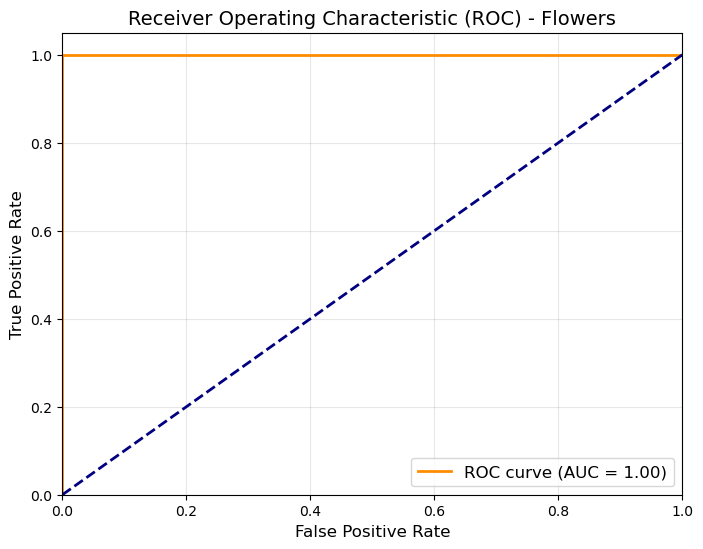

In [114]:
import matplotlib.pyplot as plt

# 1. Set up the figure size
plt.figure(figsize=(8, 6))

# 2. Plot the actual ROC curve (including your AUC score in the label)
plt.plot(
    fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.2f})'
)

# 3. Plot the diagonal baseline (random guess line)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

# 4. Add labels, limits, and grid
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) - Flowers', fontsize=14)
plt.legend(loc='lower right', fontsize=12)
plt.grid(alpha=0.3)

# 5. Display the plot
plt.show()

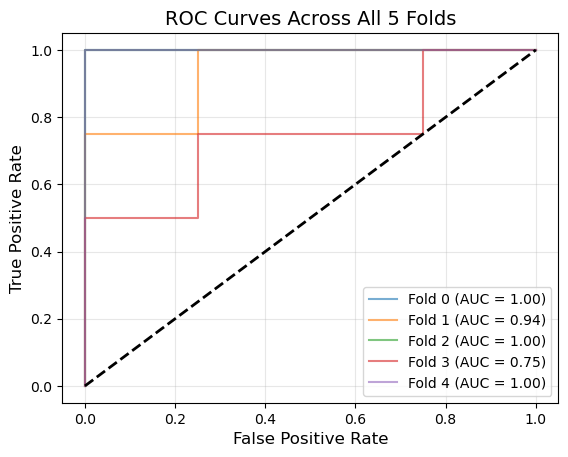

In [89]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for i, (train_index, test_index) in enumerate(skf.split(X, y)):
  X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
  y_tr, y_te = y.iloc[train_index], y.iloc[test_index]

  # Train & Predict
  model.fit(X_tr, y_tr)
  y_prob = model.predict_proba(X_te)[:, 1]

  # Calculate ROC & AUC for this fold
  fold_auc = metrics.roc_auc_score(y_te, y_prob)
  fold_fpr, fold_tpr, _ = metrics.roc_curve(y_te, y_prob, pos_label='rose')

  # Plot it
  plt.plot(
      fold_fpr, fold_tpr, alpha=0.6, label=f'Fold {i} (AUC = {fold_auc:.2f})'
  )

# Add random guess line and cleanup
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves Across All 5 Folds', fontsize=14)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

IndexError: list index out of range

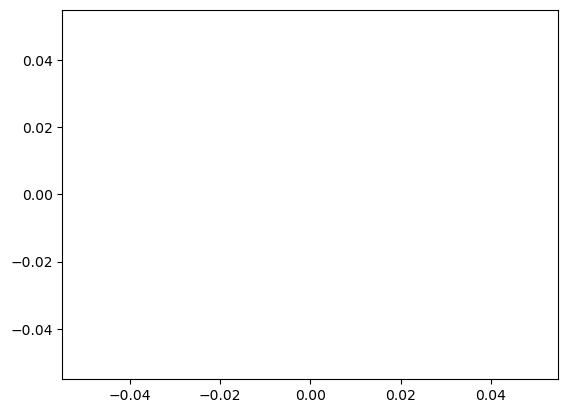

In [98]:
axes = plt.plot()

fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba, pos_label='rose')
axes[1].plot(fpr, tpr, color='darkorange')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Willekeurige gokker (AUC = 0.50)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificiteit)')
axes[1].set_ylabel('True Positive Rate (Recall / Sensitiviteit)')
axes[1].set_title(f'ROC-curve')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()